In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

import warnings
warnings.filterwarnings('ignore')


sns.set_theme(style="whitegrid")

df = pd.read_csv('../Data/CleanedData.csv')

In [2]:
feature_cols = [
    'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 
    'waterfront', 'view', 'condition', 'grade', 'zipcode', 
    'lat', 'long', 'sqft_living15', 'sqft_lot15', 'has_basement', 
    'sale_year', 'sale_month', 'house_age', 'is_renovated', 
    'years_since_renovation', 'living_to_lot_ratio'
]


X = df[feature_cols]
y = df['log_price']  

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape[0]:,} samples")
print(f"Testing set size: {X_test.shape[0]:,} samples")

Training set size: 17,289 samples
Testing set size: 4,323 samples


In [3]:
poly_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=100.0))  
])

models = {
    'Linear Regression': LinearRegression(),
    'Polynomial Regression': poly_pipeline,
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(
        n_estimators=200, 
        learning_rate=0.08, 
        max_depth=6, 
        subsample=0.8, 
        colsample_bytree=0.8, 
        random_state=42, 
        n_jobs=-1
    )
}

results = []
trained_models = {}



In [4]:

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    
   
    preds_log = model.predict(X_test)
    

    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test)
    

    r2 = r2_score(y_test, preds_log)
    rmse = np.sqrt(mean_squared_error(y_test_actual, preds_actual))
    mae = mean_absolute_error(y_test_actual, preds_actual)
    
    results.append({
        'Model': name,
        'R2 Score': r2,
        'RMSE ($)': rmse,
        'MAE ($)': mae
    })


results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)
results_df

,Model,R2 Score,RMSE ($),MAE ($)
0,XGBoost,0.909803,119932.589437,64599.449648
1,Random Forest,0.889783,139933.317233,72425.396154
2,Polynomial Regression,0.832066,164024.745931,92827.065724
3,Linear Regression,0.778078,255705.375094,113986.743297


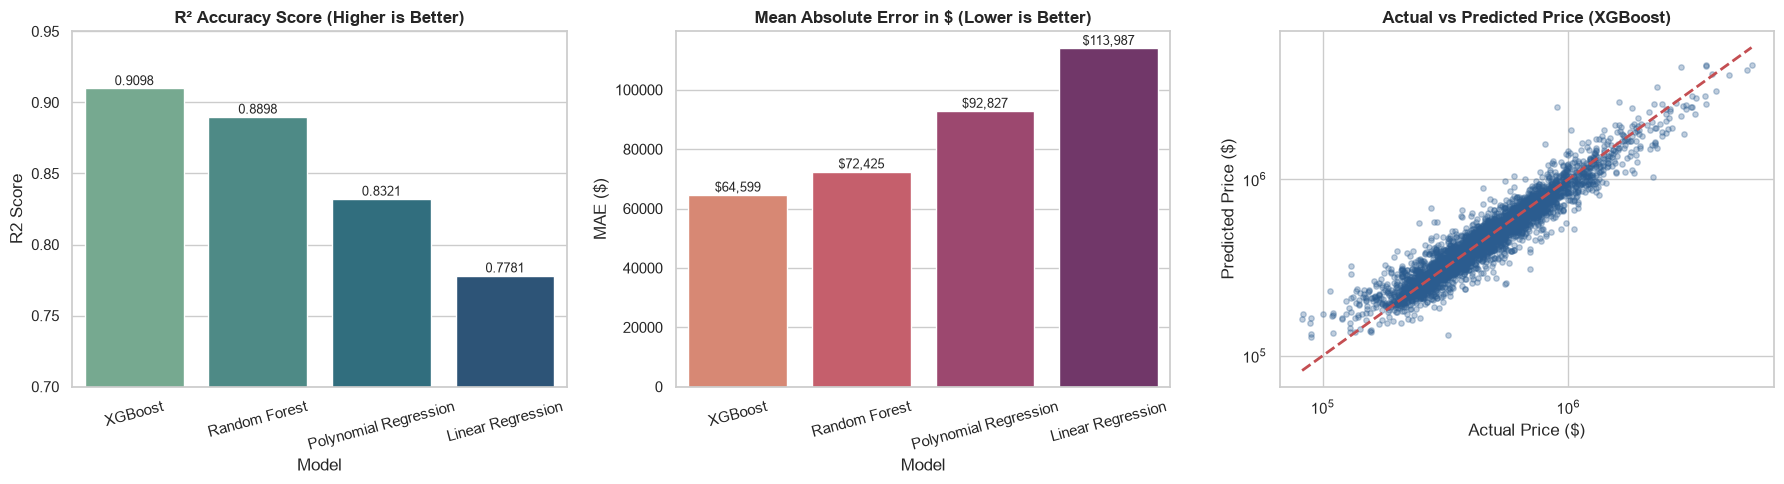

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. R2 Score Comparison Bar Plot
sns.barplot(data=results_df, x='Model', y='R2 Score', ax=axes[0], palette='crest')
axes[0].set_title('R² Accuracy Score (Higher is Better)', fontweight='bold')
axes[0].set_ylim(0.7, 0.95)
axes[0].tick_params(axis='x', rotation=15)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

# 2. Mean Absolute Error ($) Bar Plot
sns.barplot(data=results_df, x='Model', y='MAE ($)', ax=axes[1], palette='flare')
axes[1].set_title('Mean Absolute Error in $ (Lower is Better)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=15)
for p in axes[1].patches:
    axes[1].annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

# 3. Actual vs Predicted Price (Best Performing Model)
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
y_pred_best = np.expm1(best_model.predict(X_test))
y_test_actual = np.expm1(y_test)

axes[2].scatter(y_test_actual, y_pred_best, alpha=0.3, color='#2b5c8f', s=15)
axes[2].plot([y_test_actual.min(), y_test_actual.max()], [y_test_actual.min(), y_test_actual.max()], 'r--', lw=2)
axes[2].set_title(f'Actual vs Predicted Price ({best_model_name})', fontweight='bold')
axes[2].set_xlabel('Actual Price ($)')
axes[2].set_ylabel('Predicted Price ($)')
axes[2].set_xscale('log')
axes[2].set_yscale('log')

plt.tight_layout()
plt.show()

In [6]:
best_model_name = results_df.iloc[0]['Model']
best_model_instance = trained_models[best_model_name]

joblib.dump(best_model_instance, '../Data/best_house_price_model.pkl')
joblib.dump(feature_cols, '../Data/model_features.pkl')

print(f"Top Model ('{best_model_name}') saved to 'best_house_price_model.pkl'")

Top Model ('XGBoost') saved to 'best_house_price_model.pkl'
